## Statistics for tracks in different resolutions

This notebook contains the following plots:

1. Location: Distribution of points in latitude and longitude for all resolutions.
2. Intensity: Distribution of vortcity values for all track resolutions (maximum along a track)
3. Travel: Distance distribution for all resolutions
4. Evolution: Lifetime distribution for all resolutions

All distributions contains median vals and 1 sigma bounds. 


In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import pystormtracker as pst

module_dir = (Path.cwd() / ".." / ".." / "algorithms").resolve()
sys.path.insert(0, str(module_dir))
import helpers
from configs import REGION, DOMAIN, SL_AREA, SAMPLE_CONFIG
from plotting import setup_plotting, geo_map, add_colorbar
from helpers import tracks_to_points, haversine_km
from statistics_on_tracks import summarise_points

colors = setup_plotting()
plt.rcParams["axes.formatter.limits"] = (-4, 5)   # plain numbers on the axes (e.g. 1000 hPa, not 1.0 x 1e3)

In [5]:
TRACK_DIR = Path("/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/regrid_exp")
SAMPLE_GRID = "sl0p25"

R_EARTH_KM = 6371.0
GALE, STORM = 17.2, 24.5   # m s-1, Beaufort 8 and 10


def res_from_tag(tag):
    # '0p25' -> 0.25, '1p875' -> 1.875
    return float(tag.replace("p", "."))


def res_label(res):
    return f"{res:g}°"


print(TRACK_DIR)
sorted(p.name for p in TRACK_DIR.glob("*_DJF"))

/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/regrid_exp


['19791980_DJF',
 '19801981_DJF',
 '19811982_DJF',
 '19821983_DJF',
 '19831984_DJF',
 '19841985_DJF',
 '19851986_DJF',
 '19861987_DJF',
 '19871988_DJF',
 '19881989_DJF',
 '19891990_DJF',
 '19901991_DJF',
 '19911992_DJF',
 '19921993_DJF',
 '19931994_DJF',
 '19941995_DJF',
 '19951996_DJF',
 '19961997_DJF',
 '19971998_DJF',
 '19981999_DJF',
 '19992000_DJF',
 '20002001_DJF',
 '20012002_DJF',
 '20022003_DJF',
 '20032004_DJF',
 '20042005_DJF',
 '20052006_DJF',
 '20062007_DJF',
 '20072008_DJF',
 '20082009_DJF',
 '20092010_DJF',
 '20102011_DJF',
 '20112012_DJF',
 '20122013_DJF',
 '20132014_DJF',
 '20142015_DJF',
 '20152016_DJF',
 '20162017_DJF',
 '20172018_DJF',
 '20182019_DJF',
 '20192020_DJF',
 '20202021_DJF',
 '20212022_DJF',
 '20222023_DJF',
 '20232024_DJF',
 '20242025_DJF',
 '20252026_DJF']

In [6]:


def load_tracks_all(kind="filtered", track_dir=TRACK_DIR):
    # kind = 'filtered' or 'raw'
    tables = []
    for season_dir in sorted(p for p in track_dir.glob("*_DJF") if p.is_dir() and not p.name.startswith("._")):
        for path in sorted(season_dir.glob(f"*_vo_{kind}.trackjson")):
            if path.name.startswith("._"):
                continue
            tracks = pst.load_tracks(str(path))
            if tracks is None or len(tracks) == 0:
                continue
            df = tracks_to_points(tracks)
            df.insert(0, "season", season_dir.name)
            df.insert(1, "res", res_from_tag(path.name.split("_")[2]))   # 19981999 DJF 0p25 vo filtered.trackjson
            tables.append(df)
    out = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
    print(f"{kind}: {len(out)} points from {len(tables)} files")
    return out


points = load_tracks_all("filtered")
points["time"] = pd.to_datetime(points["time"])
points["vo_1e5"] = points["vo"] * 1e5

KEY = ["season", "res", "track_id"]
points = points.sort_values(KEY + ["time"], ignore_index=True)

# translation speed from consecutive points of the same track
same = points[KEY].eq(points[KEY].shift()).all(axis=1)
step_km = haversine_km(points["lat"].shift(), points["lon"].shift(), points["lat"], points["lon"])
dt_h = points["time"].diff() / pd.Timedelta(hours=1)
points["step_km"] = np.where(same, step_km, 0.0)
points["speed_kmh"] = np.where(same, step_km / dt_h, np.nan)

# one row per track: n_points, duration_h, genesis/lysis, vo_max, object_*_max, ...

parts = []
for (season, res), d in points.groupby(["season", "res"], sort=True):
    s = summarise_points(d.drop(columns=["season", "res"]))
    s.insert(0, "season", season)
    s.insert(1, "res", res)
    parts.append(s)
summary = pd.concat(parts, ignore_index=True).sort_values(KEY, ignore_index=True)

path = points.groupby(KEY)["step_km"].sum().rename("path_km").reset_index()
summary = summary.merge(path, on=KEY, how="left")
summary["vo_max_1e5"] = summary["vo_max"] * 1e5

RESOLUTIONS = sorted(points["res"].unique())
SEASONS = sorted(points["season"].unique())
RES_COLOR = {r: colors[i % len(colors)] for i, r in enumerate(RESOLUTIONS)}
print("seasons:", len(SEASONS), " resolutions:", RESOLUTIONS)

summary.pivot_table(index="season", columns="res", values="track_id", aggfunc="count")

filtered: 293849 points from 235 files
seasons: 47  resolutions: [np.float64(0.25), np.float64(1.25), np.float64(1.875), np.float64(2.5), np.float64(3.0)]


res,0.250,1.250,1.875,2.500,3.000
season,,,,,
19791980_DJF,124,120,94,54,40
19801981_DJF,122,106,85,56,30
19811982_DJF,126,117,86,40,29
19821983_DJF,116,101,85,49,35
19831984_DJF,109,106,97,47,37
19841985_DJF,116,117,91,47,28
19851986_DJF,111,112,85,49,31
19861987_DJF,114,101,79,54,35
19871988_DJF,122,113,89,62,22


In [7]:
print(summary.keys())

Index(['season', 'res', 'track_id', 'n_points', 'start_time', 'end_time',
       'lat_genesis', 'lon_genesis', 'lat_lysis', 'lon_lysis', 'duration_h',
       'object_gridcell_area_km2_max', 'object_moment_fitted_area_km2_max',
       'object_moment_major_axis_km_max', 'object_moment_minor_axis_km_max',
       'object_moment_orientation_degrees_max', 'raw_value_max', 'vo_max',
       'vo_1e5_max', 'step_km_max', 'speed_kmh_max', 'path_km', 'vo_max_1e5'],
      dtype='str')


In [8]:
points

,season,res,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo,vo_1e5,step_km,speed_kmh
0,19791980_DJF,0.25,8,1979-12-01 00:00:00,48.25,-41.25,0.0,0.0,0.0,0.0,0.0,0.000025,0.000025,2.512980,0.000000,NaN
1,19791980_DJF,0.25,8,1979-12-01 06:00:00,49.00,-34.50,0.0,0.0,0.0,0.0,0.0,0.000023,0.000023,2.342752,502.896531,83.816088
2,19791980_DJF,0.25,8,1979-12-01 12:00:00,50.75,-25.75,0.0,0.0,0.0,0.0,0.0,0.000028,0.000028,2.803355,656.066844,109.344474
3,19791980_DJF,0.25,8,1979-12-01 18:00:00,50.25,-21.50,0.0,0.0,0.0,0.0,0.0,0.000023,0.000023,2.252798,305.649750,50.941625
4,19791980_DJF,0.25,8,1979-12-02 00:00:00,46.75,-22.00,0.0,0.0,0.0,0.0,0.0,0.000022,0.000022,2.180087,390.919376,65.153229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293844,20252026_DJF,3.00,15174,2026-02-16 18:00:00,45.00,-51.00,0.0,0.0,0.0,0.0,0.0,0.000078,0.000078,7.822118,235.866586,39.311098
293845,20252026_DJF,3.00,15174,2026-02-17 00:00:00,45.00,-45.00,0.0,0.0,0.0,0.0,0.0,0.000099,0.000099,9.901715,471.652288,78.608715
293846,20252026_DJF,3.00,15174,2026-02-17 06:00:00,45.00,-39.00,0.0,0.0,0.0,0.0,0.0,0.000085,0.000085,8.463784,471.652288,78.608715
293847,20252026_DJF,3.00,15174,2026-02-17 12:00:00,45.00,-36.00,0.0,0.0,0.0,0.0,0.0,0.000047,0.000047,4.711302,235.866586,39.311098


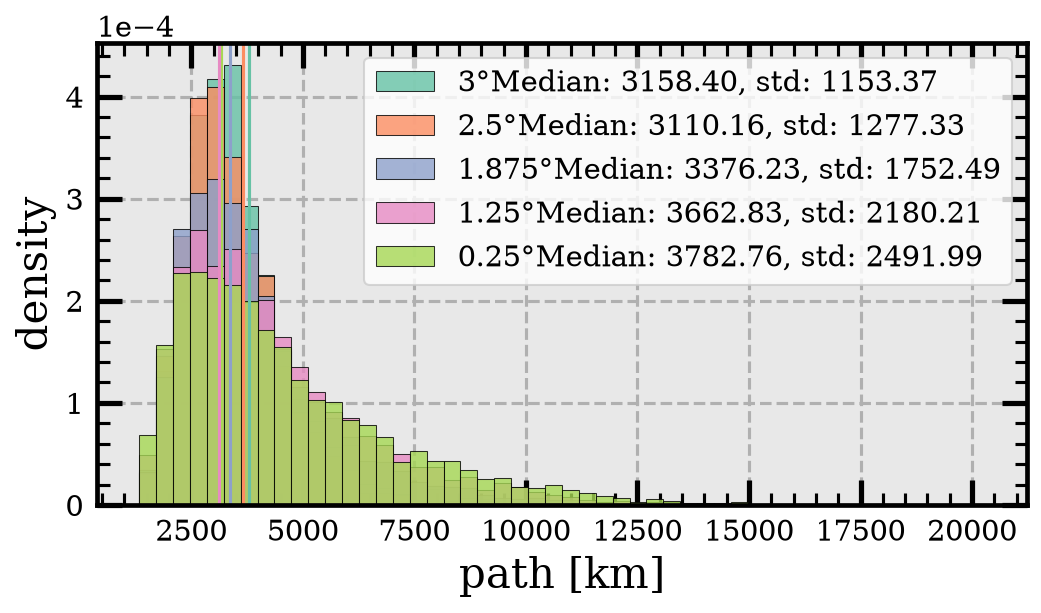

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
Nbins = 50
min_val=summary["path_km"].min()
max_val=summary["path_km"].max()
for res in RESOLUTIONS[::-1]:  # plot coarsest first, so finest is on top
    d = summary[summary["res"] == res]
    counts, edges = np.histogram(d["path_km"], bins=Nbins, range=(min_val, max_val), density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])


    median = np.median(d["path_km"])
    sigma = np.std(d["path_km"])

    ax.axvline(median, color=RES_COLOR[res], linestyle="-")    
    ax.hist(centers, bins=Nbins, weights=counts, label=res_label(res) + f"Median: {median:.2f}, std: {sigma:.2f}", alpha=0.8, edgecolor="black", linewidth=0.5)
   
ax.set_xlabel("path [km]")
ax.set_ylabel("density")
ax.legend()  

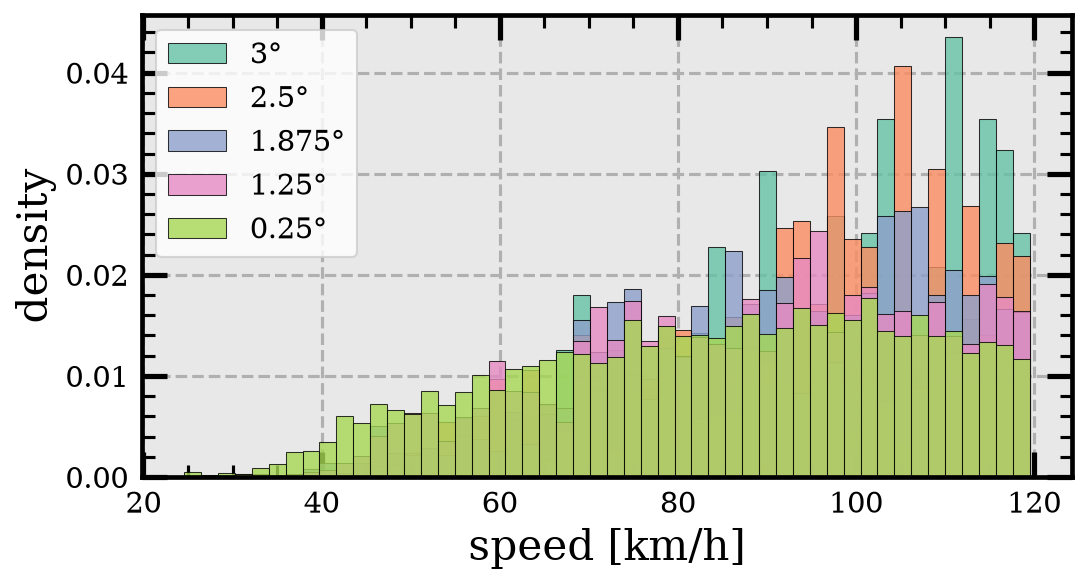

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
Nbins = 50
min_val=summary["speed_kmh_max"].min()
max_val=summary["speed_kmh_max"].max()
for res in RESOLUTIONS[::-1]:  # plot coarsest first, so finest is on top
    d = summary[summary["res"] == res]
    counts, edges = np.histogram(d["speed_kmh_max"], bins=Nbins, range=(min_val, max_val), density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.hist(centers, bins=Nbins, weights=counts, label=res_label(res), alpha=0.8, edgecolor="black", linewidth=0.5)
ax.set_xlabel("speed [km/h]")
ax.set_ylabel("density")
ax.legend()  

In [11]:
def boot_hist(x, edges, groups=None, n_boot=1000, ci=(2.5, 97.5), seed=0):
    """Density histogram + bootstrap CI. If `groups` (e.g. track ids) is given,
    whole groups are resampled (block bootstrap); otherwise individual values."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    dens, _ = np.histogram(x, bins=edges, density=True)
    if groups is None:
        samples = (x[rng.integers(0, len(x), len(x))] for _ in range(n_boot))
    else:
        groups = np.asarray(groups)
        blocks = [x[groups == g] for g in np.unique(groups)]
        samples = (np.concatenate([blocks[k] for k in rng.integers(0, len(blocks), len(blocks))])
                   for _ in range(n_boot))
    boot = np.array([np.histogram(s, bins=edges, density=True)[0] for s in samples])
    lo, hi = np.percentile(boot, ci, axis=0)
    return dens, lo, hi



def plot_dist(ax, df, var, xlabel, nbins=30, unit="", group_col=None, clip_pct=99):
    vals = df[var].dropna()
    edges = np.linspace(vals.min(), vals.max())

    for res in RESOLUTIONS[::-1]:          # coarsest first, finest drawn on top
        d = df[df["res"] == res].dropna(subset=[var])
        x = d[var].to_numpy()
        g = d[group_col].to_numpy() if group_col else None
        c = RES_COLOR[res]

        dens, lo, hi = boot_hist(x, edges, groups=g)
        ax.fill_between(edges[:-1], lo, hi, step="post", color=c, alpha=0.2, lw=0)
        ax.stairs(dens, edges, color=c, lw=1.8,
                  label=f"{res_label(res)}  (n={len(x)}, median {np.median(x):.2f}{unit})")
        ax.axvline(np.median(x), color=c, ls="--", lw=1.2)

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability density")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    ax.set_axisbelow(True)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=True, fontsize=9)   # finest first




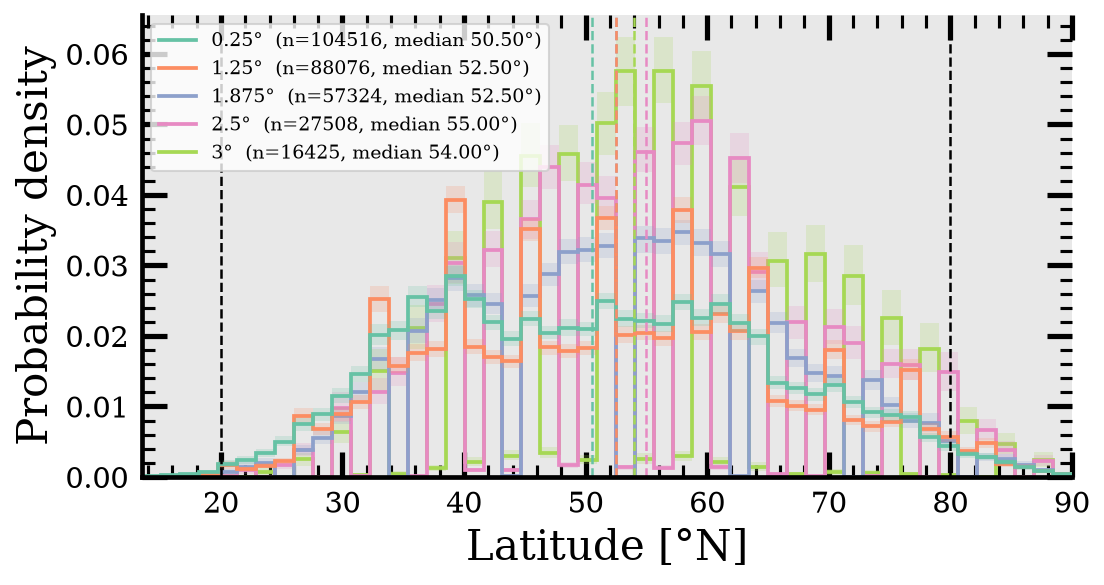

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

plot_dist(ax, points, "lat", "Latitude [°N]", nbins=30, unit="°", group_col="track_id")
ax.vlines([REGION[1], REGION[3]], *ax.get_ylim(), color="black", ls="--", lw=1.2, label="Region bounds")
#ax.legend()

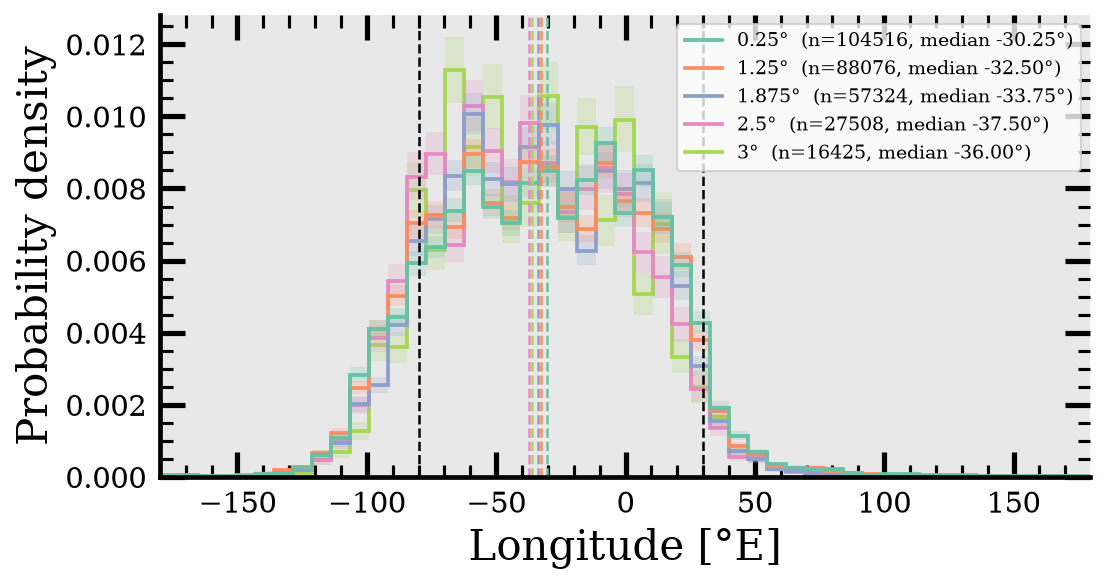

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_dist(ax, points, "lon", "Longitude [°E]", nbins=30, unit="°", group_col="track_id")
ax.vlines([REGION[0], REGION[2]], *ax.get_ylim(), color="black", ls="--", lw=1.2, label="Region bounds")

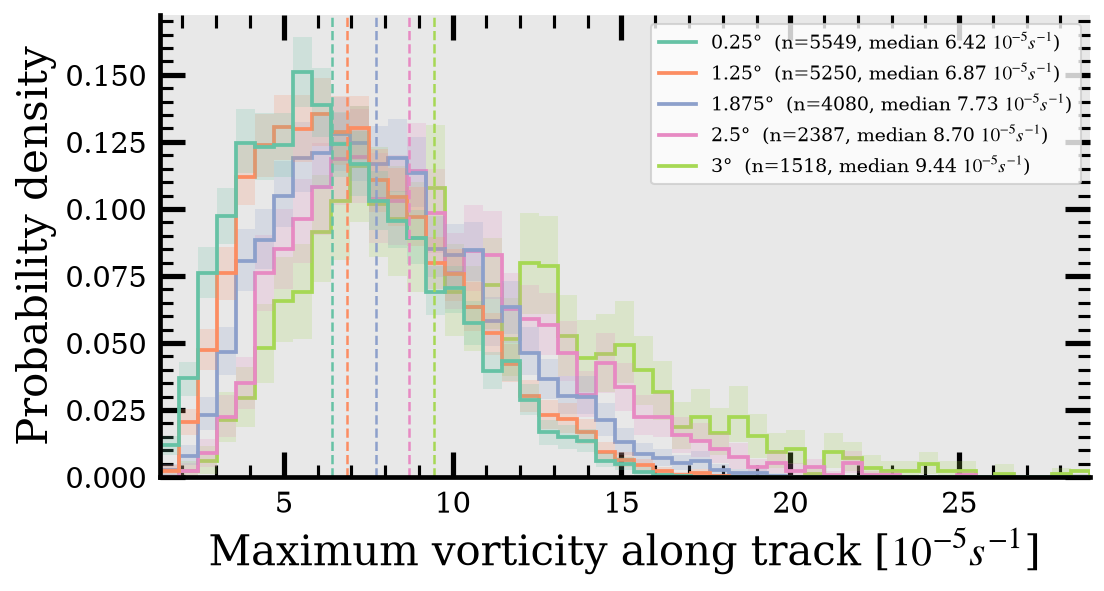

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_dist(ax, summary, "vo_1e5_max", "Maximum vorticity along track [$10^{-5} s^{-1}$]", unit=" $10^{-5} s^{-1}$")

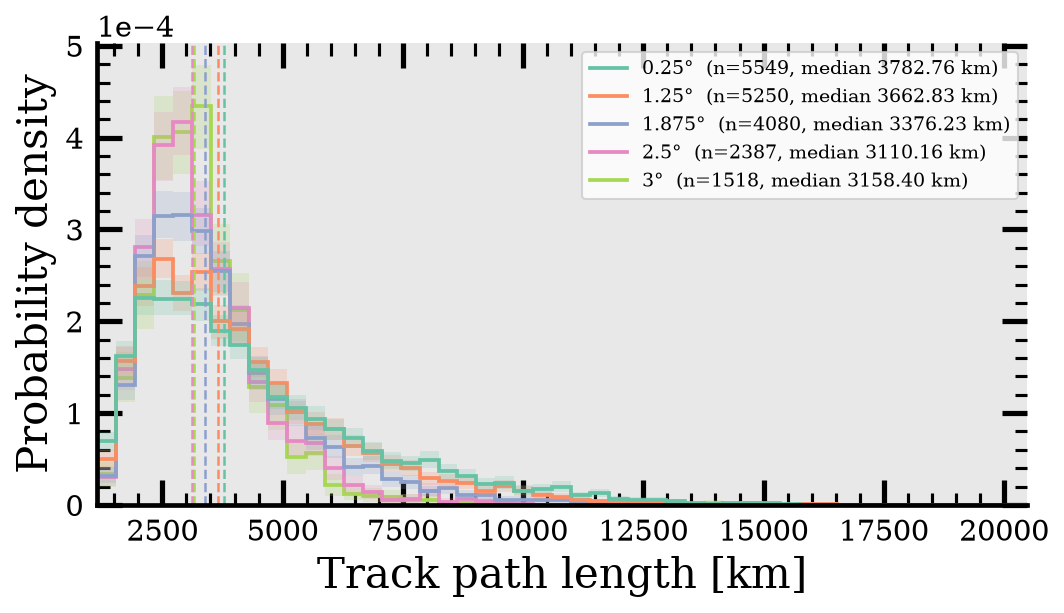

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_dist(ax, summary, "path_km", "Track path length [km]", unit=" km")

(45.0, 300.0)

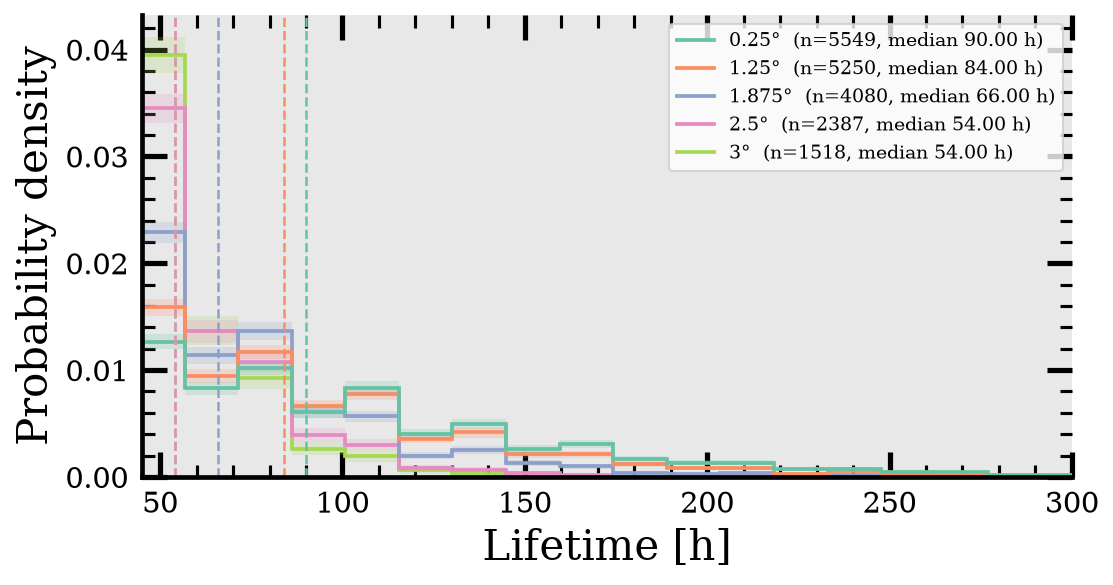

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))

plot_dist(ax, summary, "duration_h", "Lifetime [h]", unit=" h", nbins=100, group_col="track_id")
ax.set_xlim(45, 300)

I wrote this to commit again.

In [17]:
#new changes